In [1]:
# Carga las herramientas de lectura, validación y presentación del análisis.
from pathlib import Path
import pandas as pd
import numpy as np
import hashlib
from IPython.display import display, SVG
from html import escape

# Localiza la fuente desde la raíz o notebooks/ y detiene la ejecución si no existe.
RAIZ = Path.cwd().resolve()
if not (RAIZ / "datos/sales.csv").is_file():
    RAIZ = RAIZ.parent
if not (RAIZ / "datos/sales.csv").is_file():
    raise FileNotFoundError("Abre el notebook desde la raíz del proyecto o notebooks/.")

# Exploración de sales.csv

Objetivo: conocer estructura, calidad y cobertura de las ventas físicas antes de definir las métricas. Una fila registra un producto, cantidad, monto, tienda y comprobante; la fuente no incluye una clave explícita para reunir las filas como tickets completos. Este notebook no modifica las fuentes ni calcula ventas netas definitivas.

## Documentación relacionada

- [Informe de resultados aislados de sales](../docs/02_exploracion/resultados_sales.md): resultados, interpretación, importancia y límites.

Analizo únicamente sales.csv; no realizo cruces con otras fuentes.

## Lectura de archivo

In [2]:
# Lee la fuente original y exige el esquema mínimo antes de continuar.
ARCHIVO = RAIZ / "datos/sales.csv"
sales = pd.read_csv(ARCHIVO)
columnas_esperadas = {"venta_id", "fecha_hora", "tienda_id", "sku", "cantidad", "monto", "moneda", "tipo_comprobante"}
faltantes = columnas_esperadas - set(sales.columns)
if faltantes:
    raise ValueError(f"Faltan columnas requeridas: {sorted(faltantes)}")

# Identifica la versión mediante tamaño y SHA-256 y muestra una primera vista de los registros.
display(pd.DataFrame([{
    "archivo": ARCHIVO.name,
    "bytes": ARCHIVO.stat().st_size,
    "sha256": hashlib.sha256(ARCHIVO.read_bytes()).hexdigest(),
    "columnas_adicionales": sorted(set(sales.columns) - columnas_esperadas),
}]))
sales.head()

Out[1]: 
    venta_id        fecha_hora tienda_id  ...   monto  moneda  tipo_comprobante
0  V00000030  01/10/2024 12:24      T004  ...  213.75     MXN                 I
1  V00000099  01/10/2024 12:24      T022  ...  374.78     MXN                 I
2  V00000315  03/10/2024 13:19      T008  ...  587.59     MXN                 I
3  V00000378  03/10/2024 13:19      T026  ...  361.61     MXN                 I
4  V00000980  07/10/2024 12:13      T035  ...  165.88     MXN                 I

[5 rows x 8 columns]


,archivo,bytes,sha256,columnas_adicionales
0,sales.csv,4904088,1a456213c5590cf8c8d93438caf52c872ba4abd64a1b70...,[]


## Número de registros y columnas

In [3]:
# Resume dimensiones y tipos inferidos durante la lectura del CSV.
print(f"Número de registros: {len(sales)}")
print(f"Número de columnas: {len(sales.columns)}")

print("\n")
print("Columnas y tipos de datos:")
print(sales.dtypes)

Número de registros: 86490
Número de columnas: 8


Columnas y tipos de datos:
venta_id             object
fecha_hora           object
tienda_id            object
sku                  object
cantidad              int64
monto               float64
moneda               object
tipo_comprobante     object
dtype: object


## Número de valores nulos por columna

In [4]:
# Cuenta los valores ausentes reconocidos por pandas en cada campo.
print(sales.isna().sum())

venta_id            0
fecha_hora          0
tienda_id           0
sku                 0
cantidad            0
monto               0
moneda              0
tipo_comprobante    0
dtype: int64


## Significado de cada columna

| Columna | Interpretación de trabajo |
|---|---|
| venta_id | Identificador del registro; comprobar unicidad. |
| fecha_hora | Fecha y hora original, leída como texto. |
| tienda_id | Código de la tienda física. |
| sku | Código del producto en POS. |
| cantidad | Cantidad registrada sin unidad física explícita. |
| monto | Importe registrado sin desglose financiero ni base de cálculo explícita. |
| moneda | Moneda del importe. |
| tipo_comprobante | Clave original del comprobante; no determina por sí sola el signo analítico. |

Los tipos, nulos y valores distintos se calculan a continuación para evitar cifras desactualizadas.

In [5]:
# Resume esquema, completitud y variedad de valores sin escribir conteos manuales.
resumen_columnas = pd.DataFrame({
    "tipo_leido": sales.dtypes.astype(str),
    "nulos": sales.isna().sum(),
    "valores_distintos": sales.nunique(dropna=True),
})
resumen_columnas

Out[1]: 
                 tipo_leido  nulos  valores_distintos
venta_id             object      0              86490
fecha_hora           object      0              77844
tienda_id            object      0                 40
sku                  object      0                 70
cantidad              int64      0                 16
monto               float64      0              45514
moneda               object      0                  1
tipo_comprobante     object      0                  5


### Tratamiento descriptivo de comprobantes

Conservo las claves y sus importes originales y los muestro por separado. Las letras no establecen por sí solas el signo analítico ni el efecto sobre inventario; no asigno signos ni descuento unidades automáticamente.

## Calidad: vacíos, espacios e identificadores

Un duplicado exacto y un identificador repetido son controles diferentes. Los espacios se detectan sin cambiar el valor original.

In [6]:
# Revisa vacíos y espacios sin modificar los textos originales.
texto = sales.select_dtypes(include=["object", "string"])
calidad_texto = pd.DataFrame({
    "Vacios_O_Espacios": texto.apply(lambda s: s.str.fullmatch(r"\s*", na=False).sum()),
    "Espacios_En_Extremos": texto.apply(lambda s: (s.notna() & s.ne(s.str.strip())).sum()),
})

# Comprueba por separado filas idénticas e identificadores repetidos.
print("Duplicados exactos adicionales:", sales.duplicated().sum())
print("Filas adicionales con venta_id repetido:", sales.duplicated("venta_id").sum())
calidad_texto

Duplicados exactos adicionales: 0
Filas adicionales con venta_id repetido: 0
Out[1]: 
                  Vacios_O_Espacios  Espacios_En_Extremos
venta_id                          0                     0
fecha_hora                        0                     0
tienda_id                         0                     0
sku                               0                     0
moneda                            0                     0
tipo_comprobante                  0                     0


## Fechas y cobertura

Se interpreta el formato DD/MM/YYYY HH:MM de la fuente actual. Los errores quedan como NaT y se cuentan. No se infiere zona horaria ni se reconstruyen segundos.

In [7]:
# Interpreta el formato de fecha acordado y prepara una copia analítica con números finitos.
fecha = pd.to_datetime(sales["fecha_hora"], format="%d/%m/%Y %H:%M", errors="coerce")
sales_eda = sales.assign(fecha=fecha)
for columna in ["cantidad", "monto"]:
    sales_eda[columna] = pd.to_numeric(sales[columna], errors="coerce")
    sales_eda.loc[~np.isfinite(sales_eda[columna]), columna] = np.nan

# Informa cobertura y fechas rechazadas para hacer visibles los límites de la lectura.
print("Fechas sin interpretar:", sales_eda["fecha"].isna().sum())
print("Inicio:", sales_eda["fecha"].min())
print("Fin:", sales_eda["fecha"].max())
print("Tiendas:", sales["tienda_id"].nunique())
print("SKU POS:", sales["sku"].nunique())
sales_eda.loc[sales_eda["fecha"].isna(), ["venta_id", "fecha_hora"]].head()

Fechas sin interpretar: 0
Inicio: 2024-10-01 07:04:00
Fin: 2026-03-31 21:08:00
Tiendas: 40
SKU POS: 70
Out[1]: 
Empty DataFrame
Columns: [venta_id, fecha_hora]
Index: []


## Granularidad y coincidencias entre registros

Una compra puede incluir varios productos y exportarse como varias filas, cada una con su propio identificador. Que `venta_id` sea único solo demuestra unicidad del registro, no qué entidad identifica.

Se buscan filas con **la misma tienda y la misma fecha/hora registrada**, distinguiendo grupos con varios SKU. También se revisan coincidencias que comparten moneda y comprobante. Son candidatos de revisión, no tickets reconstruidos: dos clientes o cajas pueden registrar compras en el mismo minuto y una compra puede abarcar más de un minuto. La fuente no permite identificar al cliente ni confirmar pertenencia al mismo ticket por esta coincidencia.

In [8]:
# Comprueba unicidad del identificador y coincidencias por tienda y minuto, sin reconstruir tickets.
por_venta_id = sales.groupby("venta_id", dropna=False).agg(filas=("sku", "size"), productos=("sku", "nunique"))
base_coincidencias = sales_eda.loc[sales_eda["tienda_id"].notna() & sales_eda["fecha"].notna()].copy()
por_tienda_fecha = base_coincidencias.groupby(["tienda_id", "fecha"]).agg(
    registros=("venta_id", "size"),
    productos=("sku", "nunique"),
    comprobantes=("tipo_comprobante", "nunique"))
coincidencias = por_tienda_fecha.loc[por_tienda_fecha["registros"].gt(1)]
coincidencias_multisku = coincidencias.loc[coincidencias["productos"].gt(1)]

# Refina las coincidencias con moneda y comprobante iguales; esto tampoco confirma una compra común.
claves_candidatas = ["tienda_id", "fecha", "moneda", "tipo_comprobante"]
por_clave_candidata = base_coincidencias.groupby(claves_candidatas, dropna=False).agg(
    registros=("venta_id", "size"),
    productos=("sku", "nunique"))
candidatos_multisku = por_clave_candidata.loc[por_clave_candidata["registros"].gt(1) & por_clave_candidata["productos"].gt(1)]

# Cuantifica coincidencias y exclusiones sin convertir grupos temporales en tickets.
resumen_granularidad = pd.Series({
    "venta_id_con_varias_filas": int(por_venta_id["filas"].gt(1).sum()),
    "grupos_tienda_fecha_con_varias_filas": len(coincidencias),
    "filas_en_coincidencias_tienda_fecha": int(coincidencias["registros"].sum()),
    "grupos_tienda_fecha_con_varios_sku": len(coincidencias_multisku),
    "filas_en_grupos_tienda_fecha_multisku": int(coincidencias_multisku["registros"].sum()),
    "grupos_multisku_misma_moneda_y_comprobante": len(candidatos_multisku),
    "filas_en_grupos_multisku_misma_moneda_y_comprobante": int(candidatos_multisku["registros"].sum()),
    "filas_excluidas_por_tienda_o_fecha_ausente": len(sales_eda) - len(base_coincidencias),
}, name="resultado")
display(resumen_granularidad)

# Recupera ejemplos reproducibles y valida que el cruce de detalle no multiplique filas.
ejemplos_grupos = candidatos_multisku.reset_index().sort_values(["registros", "tienda_id", "fecha", "moneda", "tipo_comprobante"], ascending=[False, True, True, True, True]).head(5)
ejemplos_coincidencias = base_coincidencias.merge(ejemplos_grupos[claves_candidatas], on=claves_candidatas, how="inner", validate="many_to_one")
ejemplos_coincidencias = ejemplos_coincidencias.sort_values(claves_candidatas + ["sku", "venta_id"])
display(ejemplos_grupos)
display(ejemplos_coincidencias[["tienda_id", "fecha_hora", "venta_id", "sku", "cantidad", "monto", "moneda", "tipo_comprobante"]])
print("Coincidencia compatible con varias líneas de compra; no confirma mismo ticket ni mismo cliente. Se requiere ticket_id y el diccionario del POS.")

Coincidencia compatible con varias líneas de compra; no confirma mismo ticket ni mismo cliente. Se requiere ticket_id y el diccionario del POS.


venta_id_con_varias_filas                                0
grupos_tienda_fecha_con_varias_filas                   201
filas_en_coincidencias_tienda_fecha                    402
grupos_tienda_fecha_con_varios_sku                     201
filas_en_grupos_tienda_fecha_multisku                  402
grupos_multisku_misma_moneda_y_comprobante             186
filas_en_grupos_multisku_misma_moneda_y_comprobante    372
filas_excluidas_por_tienda_o_fecha_ausente               0
Name: resultado, dtype: int64

,tienda_id,fecha,moneda,tipo_comprobante,registros,productos
0,T001,2025-01-04 12:17:00,MXN,I,2,2
1,T001,2025-07-20 13:59:00,MXN,I,2,2
2,T001,2025-09-08 15:39:00,MXN,I,2,2
3,T001,2025-12-20 07:48:00,MXN,I,2,2
4,T001,2026-01-25 08:07:00,MXN,I,2,2


,tienda_id,fecha_hora,venta_id,sku,cantidad,monto,moneda,tipo_comprobante
0,T001,04/01/2025 12:17,V00015071,CN-00021,1.0,26.54,MXN,I
1,T001,04/01/2025 12:17,V00015073,CN-00048,3.0,72.07,MXN,I
2,T001,20/07/2025 13:59,V00046307,CN-00023,1.0,154.24,MXN,I
3,T001,20/07/2025 13:59,V00046331,CN-00058,1.0,77.75,MXN,I
4,T001,08/09/2025 15:39,V00054285,CN-00031,1.0,555.49,MXN,I
5,T001,08/09/2025 15:39,V00054313,CN-00045,1.0,96.99,MXN,I
6,T001,20/12/2025 07:48,V00070557,CN-00013,1.0,206.49,MXN,I
7,T001,20/12/2025 07:48,V00070556,CN-00017,1.0,168.98,MXN,I
8,T001,25/01/2026 08:07,V00076329,CN-00017,1.0,162.10,MXN,I
9,T001,25/01/2026 08:07,V00076280,CN-00038,2.0,693.50,MXN,I


In [9]:
# Construye las claves temporales y el calendario completo de meses observados.
sales_eda["mes"] = sales_eda["fecha"].dt.to_period("M")
sales_eda["dia"] = sales_eda["fecha"].dt.normalize()
meses = pd.period_range(sales_eda["mes"].min(), sales_eda["mes"].max(), freq="M")

# Incluye meses ausentes como desconocidos y describe tiendas y productos presentes por mes.
registros_mensuales = sales_eda.groupby("mes").agg(
    registros=("venta_id", "size"), tiendas=("tienda_id", "nunique"), productos=("sku", "nunique"))
registros_mensuales = registros_mensuales.reindex(meses)
registros_mensuales["sin_registros"] = registros_mensuales["registros"].isna()
registros_mensuales.index.name = "mes"
registros_mensuales

Out[1]: 
         registros  tiendas  productos  sin_registros
mes                                                  
2024-10       4849       40         70          False
2024-11       4886       40         70          False
2024-12       4887       40         70          False
2025-01       4907       40         70          False
2025-02       4430       40         70          False
2025-03       4769       40         70          False
2025-04       4746       40         70          False
2025-05       4851       40         70          False
2025-06       4786       40         70          False
2025-07       5016       40         70          False
2025-08       5023       40         70          False
2025-09       4718       40         70          False
2025-10       4910       40         70          False
2025-11       4713       40         70          False
2025-12       4893       40         70          False
2026-01       4876       40         70          False
2026-02       4442 

In [10]:
# Cuenta días con y sin registros por tienda; una ausencia no demuestra ventas cero.
dias = pd.date_range(sales_eda["dia"].min(), sales_eda["dia"].max(), freq="D")
actividad = sales_eda.groupby(["tienda_id", "dia"]).size().unstack(fill_value=0)
actividad = actividad.reindex(columns=dias, fill_value=0)
cobertura_tiendas = pd.DataFrame({
    "dias_con_registros": actividad.gt(0).sum(axis=1),
    "dias_sin_registros": actividad.eq(0).sum(axis=1),
})
cobertura_tiendas.sort_values("dias_sin_registros", ascending=False)

Out[1]: 
           dias_con_registros  dias_sin_registros
tienda_id                                        
T035                      528                  19
T034                      529                  18
T025                      530                  17
T011                      531                  16
T014                      531                  16
T033                      531                  16
T026                      531                  16
T002                      532                  15
T024                      532                  15
T015                      532                  15
T030                      533                  14
T016                      533                  14
T021                      533                  14
T009                      533                  14
T004                      534                  13
T008                      534                  13
T013                      534                  13
T003                      535            

Los días sin registros se comparan contra todo el período del archivo. No demuestran cierres, ventas cero ni datos perdidos: falta un calendario operativo.

## Cantidades e importes

Se describen valores registrados de todos los comprobantes; todavía no se interpretan como ventas netas.

In [11]:
# Describe la distribución de cantidades e importes mediante rangos y percentiles.
sales_eda[["cantidad", "monto"]].describe(percentiles=[.01, .25, .5, .75, .99])

Out[1]: 
           cantidad         monto
count  86490.000000  86490.000000
mean       1.542178    357.813086
std        1.180203    447.925993
min        1.000000     15.670000
1%         1.000000     16.980000
25%        1.000000    103.002500
50%        1.000000    225.400000
75%        2.000000    433.657500
99%        6.000000   2322.464400
max       16.000000   9714.870000


In [12]:
# Distingue ceros, negativos, desconocidos, infinitos y cantidades fraccionarias en la fuente.
numeros = sales[["cantidad", "monto"]].apply(pd.to_numeric, errors="coerce")
controles_numericos = pd.DataFrame({
    "ceros": numeros.eq(0).sum(),
    "negativos": numeros.lt(0).sum(),
    "no_numericos_o_nulos": numeros.isna().sum(),
    "infinitos": np.isinf(numeros).sum(),
})
print("Cantidades finitas no enteras:", (np.isfinite(numeros["cantidad"]) & numeros["cantidad"].mod(1).ne(0)).sum())
controles_numericos

Cantidades finitas no enteras: 0
Out[1]: 
          ceros  negativos  no_numericos_o_nulos  infinitos
cantidad      0          0                     0          0
monto         0          0                     0          0


## Monedas y comprobantes

Los importes se agrupan por moneda y tipo; no se mezclan monedas ni se supone que todos los tipos representan ingresos.

In [13]:
# Conserva separados moneda y comprobante; una suma totalmente desconocida no se convierte en cero.
resumen_comprobantes = sales_eda.groupby(["moneda", "tipo_comprobante"], dropna=False).agg(
    registros=("venta_id", "size"),
    unidades_registradas=("cantidad", lambda s: s.sum(min_count=1)),
    importe_registrado=("monto", lambda s: s.sum(min_count=1)))
resumen_comprobantes

Out[1]: 
                         registros  unidades_registradas  importe_registrado
moneda tipo_comprobante                                                     
MXN    E                      3079                4843.0          1140985.33
       I                     82518              127241.0         29503069.84
       N                       288                 407.0           100579.56
       P                       451                 692.0           160501.27
       T                       154                 200.0            42117.82


## Importe efectivo por unidad y producto

Se exploran registros I como subconjunto de diagnóstico. Monto/cantidad solo representa importe efectivo unitario si monto es el total de línea; no es un precio de lista. Las diferencias requieren contexto, no se corrigen automáticamente.

In [14]:
# Explora monto por unidad en registros I elegibles, suponiendo monto total y unidades comparables.
registros_i = sales_eda.loc[sales_eda["tipo_comprobante"].eq("I") & sales_eda["cantidad"].gt(0) & sales_eda["monto"].notna()].copy()
registros_i["importe_por_unidad"] = registros_i["monto"] / registros_i["cantidad"]
registros_i.groupby(["moneda", "sku"])["importe_por_unidad"].describe()

Out[1]: 
                  count        mean  ...         75%         max
moneda sku                           ...                        
MXN    CN-00001  1182.0   74.562420  ...   76.105000   77.630000
       CN-00002  1157.0  131.780337  ...  134.520000  137.000000
       CN-00003  1116.0  161.992923  ...  165.240000  168.528571
       CN-00004  1175.0  687.684074  ...  701.740000  716.580000
       CN-00005  1157.0   20.375104  ...   20.780000   21.220000
...                 ...         ...  ...         ...         ...
       CN-00066  1179.0   57.857282  ...   59.060000   60.250000
       CN-00067  1120.0  292.433096  ...  298.495000  304.400000
       CN-00068  1197.0   39.023469  ...   39.850000   40.650000
       CN-00069  1211.0  362.936009  ...  370.198333  378.190000
       CN-00070  1160.0  375.956867  ...  383.605000  391.965000

[70 rows x 8 columns]


## Formatos y dominios observados

Los patrones V + 8 dígitos, T + 3 dígitos y CN- + 5 dígitos describen esta fuente; no sustituyen un contrato del POS. Las claves I/E/N/P/T y MXN son referencias observadas. Una desviación se reporta para revisión, sin descartarla.

In [15]:
# Detecta identificadores fuera de los patrones observados sin validar su existencia en un catálogo.
patrones = {"venta_id": r"V\d{8}", "tienda_id": r"T\d{3}", "sku": r"CN-\d{5}"}
formato_invalido = pd.DataFrame({c: ~sales[c].astype("string").str.fullmatch(patron, na=False)
                                 for c, patron in patrones.items()})

# Señala categorías inesperadas para revisarlas, manteniendo los registros originales.
dominios = pd.Series({
    "moneda_fuera_de_MXN": (~sales["moneda"].isin(["MXN"])).sum(),
    "comprobante_fuera_de_I_E_N_P_T": (~sales["tipo_comprobante"].isin(["I", "E", "N", "P", "T"])).sum(),
}, name="filas_para_revisar")
display(formato_invalido.sum().rename("formato_invalido"))
display(dominios)
sales.loc[formato_invalido.any(axis=1)].head(10)

Out[1]: 
Empty DataFrame
Columns: [venta_id, fecha_hora, tienda_id, sku, cantidad, monto, moneda, tipo_comprobante]
Index: []


venta_id     0
tienda_id    0
sku          0
Name: formato_invalido, dtype: Int64

moneda_fuera_de_MXN               0
comprobante_fuera_de_I_E_N_P_T    0
Name: filas_para_revisar, dtype: int64

## Distribución por tienda y producto

Se conservan moneda y comprobante en las agrupaciones. Las sumas son de valores registrados, no ingresos netos. Las tablas muestran los primeros 15 grupos; las variables contienen el resumen completo. Se cuentan valores numéricos ausentes para no ocultarlos.

In [16]:
# Define una agregación común que conserva grupos con claves ausentes y muestra valores desconocidos.
def resumir(grupos):
    return sales_eda.groupby(grupos, dropna=False).agg(
        registros=("venta_id", "size"),
        unidades_registradas=("cantidad", lambda s: s.sum(min_count=1)),
        importe_registrado=("monto", lambda s: s.sum(min_count=1)),
        cantidades_desconocidas=("cantidad", lambda s: s.isna().sum()),
        importes_desconocidos=("monto", lambda s: s.isna().sum()),
    )

# Aplica el mismo resumen por tienda y SKU conservando moneda y tipo de comprobante.
por_tienda = resumir(["moneda", "tipo_comprobante", "tienda_id"])
por_sku = resumir(["moneda", "tipo_comprobante", "sku"])
display(por_tienda.head(15))
display(por_sku.head(15))
print("Grupos por tienda:", len(por_tienda), "| Grupos por SKU:", len(por_sku))

Grupos por tienda: 198 | Grupos por SKU: 337


registros  ...  importes_desconocidos
moneda tipo_comprobante tienda_id             ...                       
MXN    E                T001              75  ...                      0
                        T002              58  ...                      0
                        T003              76  ...                      0
                        T004              84  ...                      0
                        T005              84  ...                      0
                        T006              73  ...                      0
                        T007              75  ...                      0
                        T008              78  ...                      0
                        T009              72  ...                      0
                        T010              71  ...                      0
                        T011              75  ...                      0
                        T012              91  ...                      0
                        T013              74  ...                      0
                        T014             100  ...                      0
                        T015              75  ...                      0

[15 rows x 5 columns]

registros  ...  importes_desconocidos
moneda tipo_comprobante sku                  ...                       
MXN    E                CN-00001         50  ...                      0
                        CN-00002         39  ...                      0
                        CN-00003         44  ...                      0
                        CN-00004         48  ...                      0
                        CN-00005         51  ...                      0
                        CN-00006         39  ...                      0
                        CN-00007         45  ...                      0
                        CN-00008         51  ...                      0
                        CN-00009         45  ...                      0
                        CN-00010         56  ...                      0
                        CN-00011         40  ...                      0
                        CN-00012         31  ...                      0
                        CN-00013         38  ...                      0
                        CN-00014         40  ...                      0
                        CN-00015         53  ...                      0

[15 rows x 5 columns]

## Evolución mensual de unidades e importes

Se incluye todo el calendario entre la fecha mínima y máxima, por moneda y comprobante observados. Un mes ausente conserva importes desconocidos, sin rellenarlos con cero. El calendario no prueba que el archivo incluya todos los movimientos del negocio.

In [17]:
# Completa el calendario de cada moneda y comprobante sin inventar actividad para meses ausentes.
mensual_observado = resumir(["moneda", "tipo_comprobante", "mes"])
paneles = []
for moneda, comprobante in sales_eda[["moneda", "tipo_comprobante"]].drop_duplicates().itertuples(index=False, name=None):
    if pd.isna(moneda) or pd.isna(comprobante):
        continue
    panel = mensual_observado.loc[(moneda, comprobante)].reindex(meses)
    panel["sin_registros"] = panel["registros"].isna()
    panel["moneda"], panel["tipo_comprobante"] = moneda, comprobante
    panel.index.name = "mes"
    paneles.append(panel.reset_index())

# Presenta los paneles y hace visibles meses ausentes y fechas fuera de la agrupación.
mensual = pd.concat(paneles, ignore_index=True)
display(mensual)
print("Meses ausentes en todo el archivo:", registros_mensuales.index[registros_mensuales["sin_registros"]].astype(str).tolist())
print("Filas con fecha desconocida, fuera de las agrupaciones temporales:", sales_eda["fecha"].isna().sum())

Meses ausentes en todo el archivo: []
Filas con fecha desconocida, fuera de las agrupaciones temporales: 0


,mes,registros,unidades_registradas,importe_registrado,cantidades_desconocidas,importes_desconocidos,sin_registros,moneda,tipo_comprobante
0,2024-10,4621,6921.0,1636016.67,0,0,False,MXN,I
1,2024-11,4677,7337.0,1717735.60,0,0,False,MXN,I
2,2024-12,4665,7109.0,1621347.27,0,0,False,MXN,I
3,2025-01,4681,7170.0,1651207.03,0,0,False,MXN,I
4,2025-02,4213,6426.0,1487252.95,0,0,False,MXN,I
...,...,...,...,...,...,...,...,...,...
85,2025-11,8,9.0,1511.53,0,0,False,MXN,T
86,2025-12,9,16.0,3777.25,0,0,False,MXN,T
87,2026-01,1,2.0,57.29,0,0,False,MXN,T
88,2026-02,7,11.0,1735.63,0,0,False,MXN,T


## Valores atípicos dentro de cada producto

Regla exploratoria: importe unitario fuera de Q1 − 1.5×IQR y Q3 + 1.5×IQR, calculados por moneda y SKU sobre registros I. Se requieren al menos cuatro observaciones e IQR positivo. Los grupos sin variación o pequeños quedan sin evaluación; no se afirma que estén libres de errores. No se eliminan filas.

In [18]:
# Calcula cuartiles y dispersión por moneda y SKU dentro del subconjunto I elegible.
grupos = registros_i.groupby(["moneda", "sku"])["importe_por_unidad"]
registros_i["q1"] = grupos.transform(lambda s: s.quantile(.25))
registros_i["q3"] = grupos.transform(lambda s: s.quantile(.75))
registros_i["n_grupo"] = grupos.transform("size")
registros_i["iqr"] = registros_i["q3"] - registros_i["q1"]

# Evalúa límites de Tukey solo con al menos cuatro observaciones e IQR positivo; conserva todas las filas.
registros_i["evaluado_iqr"] = registros_i["n_grupo"].ge(4) & registros_i["iqr"].gt(0)
registros_i["atipico_iqr"] = registros_i["evaluado_iqr"] & (
    registros_i["importe_por_unidad"].lt(registros_i["q1"] - 1.5 * registros_i["iqr"]) |
    registros_i["importe_por_unidad"].gt(registros_i["q3"] + 1.5 * registros_i["iqr"]))
atipicos = registros_i.loc[registros_i["atipico_iqr"]]

# Muestra cobertura de la regla, alertas y ejemplos sin clasificar automáticamente los extremos como errores.
print("Filas evaluadas:", registros_i["evaluado_iqr"].sum())
print("Filas sin evaluación IQR:", (~registros_i["evaluado_iqr"]).sum())
print("Filas señaladas:", len(atipicos))
display(atipicos[["venta_id", "fecha_hora", "tienda_id", "sku", "moneda", "cantidad", "monto", "importe_por_unidad"]].head(20))
print("Ejemplos de mayor importe unitario; no implican error:")
registros_i.sort_values(["moneda", "importe_por_unidad"], ascending=[True, False])[["venta_id", "sku", "moneda", "importe_por_unidad"]].head(10)

Filas evaluadas: 82518
Filas sin evaluación IQR: 0
Filas señaladas: 0
Ejemplos de mayor importe unitario; no implican error:
Out[1]: 
        venta_id       sku moneda  importe_por_unidad
60385  V00060293  CN-00039    MXN          828.241667
38788  V00038616  CN-00039    MXN          828.240000
73990  V00073947  CN-00039    MXN          828.190000
62909  V00062827  CN-00039    MXN          828.040000
77181  V00077144  CN-00039    MXN          827.980000
9149   V00008876  CN-00039    MXN          827.970000
33411  V00033221  CN-00039    MXN          827.900000
15724  V00015466  CN-00039    MXN          827.830000
16423  V00016166  CN-00039    MXN          827.830000
8224   V00007947  CN-00039    MXN          827.800000


,venta_id,fecha_hora,tienda_id,sku,moneda,cantidad,monto,importe_por_unidad


## Gráficas de diagnóstico

SVG integrado sin dependencias adicionales de gráficos. Se muestra cada moneda por separado y solo comprobantes I, sin denominarlos ventas netas. Los meses sin registros o con importes desconocidos interrumpen las líneas. La concentración por tienda se mide sobre el importe I de toda la cobertura.

MXN | Participación de las 10 primeras: 26.28%


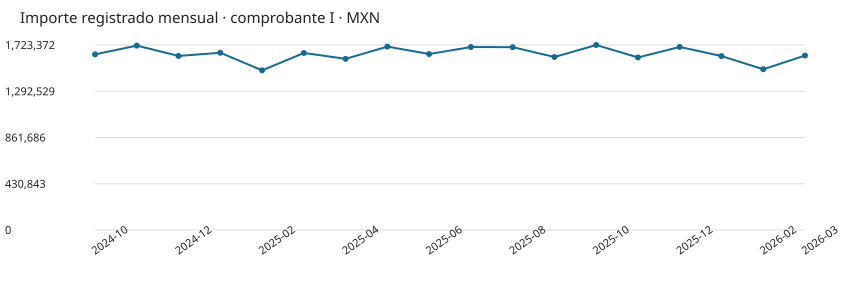

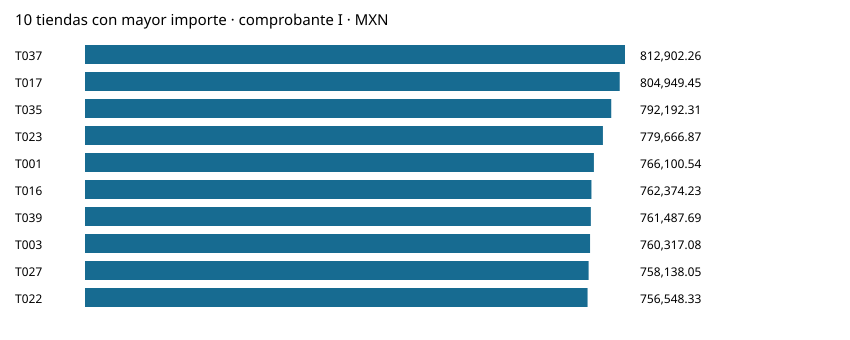

In [19]:
# Dibuja la evolución mensual en SVG e interrumpe la línea ante valores desconocidos.
def grafica_linea(serie, titulo):
    ancho, alto, izq, arriba, w, h = 850, 300, 95, 45, 710, 185
    validos = serie.dropna()
    if validos.empty:
        print(titulo, "sin valores válidos")
        return
    minimo, maximo = min(0, validos.min()), max(0, validos.max())
    rango = maximo - minimo or 1
    partes = [f'<svg xmlns="http://www.w3.org/2000/svg" viewBox="0 0 {ancho} {alto}" role="img"><title>{escape(titulo)}</title><rect width="100%" height="100%" fill="white"/><g font-family="sans-serif" font-size="11" fill="#222"><text x="20" y="23" font-size="15">{escape(titulo)}</text>']
    for k in range(5):
        valor = minimo + rango * k / 4
        y = arriba + h - h * k / 4
        partes.append(f'<line x1="{izq}" y1="{y}" x2="{izq+w}" y2="{y}" stroke="#ddd"/><text x="5" y="{y+4}">{valor:,.0f}</text>')
    previo = None
    for j, (mes, valor) in enumerate(serie.items()):
        x = izq + w * j / max(1, len(serie)-1)
        if j % 2 == 0 or j == len(serie)-1:
            partes.append(f'<text transform="translate({x},255) rotate(-35)">{escape(str(mes))}</text>')
        if pd.isna(valor):
            previo = None
            continue
        y = arriba + h - (valor-minimo)/rango*h
        if previo:
            partes.append(f'<line x1="{previo[0]}" y1="{previo[1]}" x2="{x}" y2="{y}" stroke="#176b91" stroke-width="2"/>')
        partes.append(f'<circle cx="{x}" cy="{y}" r="3" fill="#176b91"><title>{mes}: {valor:,.2f}</title></circle>')
        previo = (x,y)
    display(SVG("".join(partes) + '</g></svg>'))

# Representa la concentración por tienda para la fuente actual de importes positivos.
def grafica_barras(serie, titulo):
    maximo = serie.abs().max() or 1
    partes = [f'<svg xmlns="http://www.w3.org/2000/svg" viewBox="0 0 850 {70+len(serie)*27}" role="img"><title>{escape(titulo)}</title><rect width="100%" height="100%" fill="white"/><g font-family="sans-serif" font-size="12"><text x="15" y="25" font-size="15">{escape(titulo)}</text>']
    for j,(tienda,valor) in enumerate(serie.items()):
        y = 45+j*27
        partes.append(f'<text x="15" y="{y+15}">{escape(str(tienda))}</text><rect x="85" y="{y}" width="{max(0,valor)/maximo*540}" height="19" fill="#176b91"/><text x="640" y="{y+15}">{valor:,.2f}</text>')
    display(SVG("".join(partes)+'</g></svg>'))

# Grafica únicamente registros I por moneda y calcula la participación de las diez primeras tiendas.
participacion_tiendas = {}
for moneda in registros_i["moneda"].dropna().unique():
    panel = mensual.loc[mensual["moneda"].eq(moneda) & mensual["tipo_comprobante"].eq("I")].set_index("mes")
    serie = panel["importe_registrado"].mask(panel["importes_desconocidos"].gt(0))
    grafica_linea(serie, f"Importe registrado mensual · comprobante I · {moneda}")
    valores = registros_i.loc[registros_i["moneda"].eq(moneda)].groupby("tienda_id")["monto"].sum().sort_values(ascending=False)
    participacion_tiendas[moneda] = valores
    grafica_barras(valores.head(10), f"10 tiendas con mayor importe · comprobante I · {moneda}")
    total = valores.sum()
    print(moneda, "| Participación de las 10 primeras:", f"{valores.head(10).sum()/total:.2%}" if total else "sin base")

## Conclusiones calculadas y límites

El siguiente resumen se recalcula con la fuente actual. La ausencia de alertas describe los controles aplicados; no confirma la veracidad de cada operación ni los precios del negocio.

In [20]:
# Reúne resultados calculados y explicita las limitaciones comerciales del diagnóstico.
print(f"Fuente: {ARCHIVO.name} | {len(sales):,} registros | {len(sales.columns)} columnas.")
print(f"Cobertura: {sales_eda['fecha'].min()} a {sales_eda['fecha'].max()}.")
print(f"Tiendas: {sales['tienda_id'].nunique()} | SKU POS: {sales['sku'].nunique()}.")
print(f"Nulos originales: {sales.isna().sum().sum()} | Duplicados exactos adicionales: {sales.duplicated().sum()} | IDs repetidos adicionales: {sales.duplicated('venta_id').sum()}.")
print(f"Fechas sin interpretar: {sales_eda['fecha'].isna().sum()} | Combinaciones tienda-día sin registros: {cobertura_tiendas['dias_sin_registros'].sum()}.")
print("Monedas:", sales['moneda'].value_counts(dropna=False).to_dict())
print("Comprobantes:", sales['tipo_comprobante'].value_counts(dropna=False).to_dict())
print(f"Formatos de ID fuera de patrón: {formato_invalido.sum().sum()} | Importes/cantidades no numéricos, nulos o infinitos: {controles_numericos[['no_numericos_o_nulos', 'infinitos']].sum().sum()}.")
print(f"Atípicos unitarios I según IQR: {len(atipicos)}; filas evaluadas: {registros_i['evaluado_iqr'].sum()}.")
print("La validez numérica no confirma impuestos, descuentos, precios ni costos.")
for moneda, valores in participacion_tiendas.items():
    print(f"Mayor importe I en {moneda}: tienda {valores.index[0]} con {valores.iloc[0]:,.2f}; no mide margen ni desempeño ajustado por tamaño.")

Fuente: sales.csv | 86,490 registros | 8 columnas.
Cobertura: 2024-10-01 07:04:00 a 2026-03-31 21:08:00.
Tiendas: 40 | SKU POS: 70.
Nulos originales: 0 | Duplicados exactos adicionales: 0 | IDs repetidos adicionales: 0.
Fechas sin interpretar: 0 | Combinaciones tienda-día sin registros: 476.
Monedas: {'MXN': 86490}
Comprobantes: {'I': 82518, 'E': 3079, 'P': 451, 'N': 288, 'T': 154}
Formatos de ID fuera de patrón: 0 | Importes/cantidades no numéricos, nulos o infinitos: 0.
Atípicos unitarios I según IQR: 0; filas evaluadas: 82518.
La validez numérica no confirma impuestos, descuentos, precios ni costos.
Mayor importe I en MXN: tienda T037 con 812,902.26; no mide margen ni desempeño ajustado por tamaño.


## Conclusión

Tengo caracterizadas la estructura, calidad y cobertura de los registros físicos. Distingo importes registrados de ingresos netos y coincidencias temporales de tickets identificados; los controles describen consistencia interna, sin certificar la exactitud comercial del POS.